# W8-C: Real passage utility modeling

Run with the **sara_env** kernel, from top to bottom. The first run generates the
missing real FIT promotion surface: **1,746 queries × 6 SARA generations**. This
stage uses the TITAN RTX and resumes its cache if interrupted. Release the SARA
model from other notebook kernels before starting. Existing INTERNAL-VAL results
are preserved. There are no synthetic-data fallbacks.

U0, U1, U2-F, U2-A, U3 and U4-A are trained and compared using paper-grouped FIT
OOF predictions. Only the selected model is refitted on all FIT and evaluated on
INTERNAL-VAL. This is held out from fitting but has been inspected in earlier
development; it is not a pristine final test set. TEST remains untouched. U3 here is the lightweight joint encoder variant, not Mistral QLoRA.
U4-B awaits measured W8-D attribution features and is explicitly skipped.

Reported downstream F1 uses an **oracle gate** to isolate passage selection; it
is not the complete deployed DAFiR controller result. STOP calibration is W8-E.
W8-B token uncertainty is excluded from both splits until genuine FIT diagnostics
are available; all models see the canonical base prediction as their draft.


## SECTION 1 — Configuration and real FIT preparation


In [1]:
import sys, json, subprocess, gc, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# Discover the repository from the notebook or repository working directory.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'configs/week8/w8_dafir.yaml').is_file())
sys.path.insert(0, str(REPO_ROOT))
from src.week8.utility_training import (
    TrainingConfig, load_surface, prepare_features, run_oof, fit_final, predict_final,
)
from src.week8.utility_dataset import get_non_leaking_feature_columns
from src.week8.data import load_config, assert_paper_disjoint
from src.week8.evaluation import compute_query_grouped_selector_metrics, compute_calibration_metrics
from src.week8.utility_models import (
    S0_Rank5Selector, S1_BM25Selector, S2_SemanticSelector,
    S3_DraftSimilaritySelector, S4_MarginalInfoSelector, OracleSelector,
)

PREPARE_MISSING_FIT = True
MODELS = ['U0', 'U1', 'U2-F', 'U2-A', 'U3', 'U4-A']
TRAIN = TrainingConfig(device='cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.executable, '| Device:', TRAIN.device)
print('Training settings:', TRAIN)
cfg = load_config()
fit_manifest = pd.read_csv(REPO_ROOT / cfg['splits']['fit_manifest'], dtype=str)
fit_path = REPO_ROOT / 'results/week8/surfaces/promotion_surface_fit.jsonl'
val_path = REPO_ROOT / 'results/week8/surfaces/promotion_surface_internal_val.jsonl'
assert val_path.is_file(), 'Canonical INTERNAL-VAL surface must already exist.'
# A partial append-safe FIT cache is resumable, never accepted as a full surface.
fit_rows = pd.read_json(fit_path, lines=True) if fit_path.exists() and fit_path.stat().st_size else pd.DataFrame()
complete = (not fit_rows.empty and len(fit_rows) == 6 * len(fit_manifest)
            and set(fit_rows.question_id.astype(str)) == set(fit_manifest.question_id))
if not complete:
    if not PREPARE_MISSING_FIT:
        raise FileNotFoundError('Real FIT surface missing/incomplete. Enable PREPARE_MISSING_FIT to generate it.')
    if not torch.cuda.is_available():
        raise RuntimeError('FIT SARA generation requires the GPU. Select the sara_env kernel with CUDA.')
    free, total = torch.cuda.mem_get_info()
    print(f'FIT generation required. Free GPU memory: {free/2**30:.1f}/{total/2**30:.1f} GiB', flush=True)
    if free < 18 * 2**30:
        raise RuntimeError('Free the SARA model in other notebook kernels before generating FIT (at least 18 GiB free required). Then rerun this cell.')
    command = [sys.executable, '-u', str(REPO_ROOT / 'scripts/week8/run_w8a_promotion_surface.py'),
               '--split', 'fit', '--full', '--surface-only', '--device', TRAIN.device]
    process = subprocess.Popen(command, cwd=REPO_ROOT, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait() != 0:
            raise RuntimeError('FIT generation failed. Fix the error above and rerun; completed rows are cached.')
    except BaseException:
        process.terminate()
        process.wait()
        raise
print('Real FIT preparation complete. No model has been evaluated on INTERNAL-VAL.')


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/bin/python | Device: cuda
Training settings: TrainingConfig(n_splits=5, epochs=3, learning_rate=0.0002, backbone_learning_rate=2e-05, seed=42, max_length=512, model_name='cross-encoder/ms-marco-MiniLM-L-6-v2', device='cuda')
FIT generation required. Free GPU memory: 22.9/23.5 GiB
2026-10-17 02:39:35,013 [INFO] === Canonical W8-A Promotion Response Surface (split=fit, smoke=False, device=cuda) ===
2026-10-17 02:39:35,688 [INFO] Loaded 1746 queries for split 'fit' from /home/gunavenkat/Downloads/CS787-RAG-Project/results/week5/train_response_surface/train_retrieval.jsonl
2026-10-17 02:39:35,689 [INFO] Loaded 1746 queries for split fit
2026-10-17 02:39:35,752 [INFO] Loaded canonical base k=4 for 1746 queries. Mean F1 = 0.3856312 (Target: 0.3856312)
2026-10-17 02:39:35,752 [INFO] VERIFICATION PASSED: canonical k4 covers every requested query.
2026-10-17 02:39:35,888 [INFO] Precomputing MiniLM semantic similarity scores...
2026-1

## SECTION 2 — Validate canonical FIT and split membership


In [2]:
df_fit = load_surface('fit')
val_manifest = pd.read_csv(REPO_ROOT / cfg['splits']['internal_val_manifest'], dtype=str)
assert_paper_disjoint(set(fit_manifest.paper_id), set(val_manifest.paper_id))
assert not set(fit_manifest.question_id) & set(val_manifest.question_id)
print(f'FIT: {len(df_fit)} candidates, {df_fit.question_id.nunique()} queries, {df_fit.paper_id.nunique()} papers')
print('Six unique candidates per query; canonical W7 k4 drafts and delta labels verified.')


FIT: 10476 candidates, 1746 queries, 656 papers
Six unique candidates per query; canonical W7 k4 drafts and delta labels verified.


## SECTION 3 — Build genuine semantic and draft features


In [4]:
import importlib
import src.week8.utility_training as ut
importlib.reload(ut)
prepare_features = ut.prepare_features

In [5]:
df_fit = prepare_features(df_fit)
feature_cols = get_non_leaking_feature_columns(df_fit)
assert feature_cols and np.isfinite(df_fit[feature_cols].to_numpy(float)).all()
print('Approved pre-promotion features:', feature_cols)
print('Excluded: gold/evidence labels, promotion latency, promoted output and outcome metrics.')


Semantic/MIG features:   0%|          | 0/1746 [00:00<?, ?it/s]

Semantic/MIG features: 100%|██████████| 1746/1746 [07:00<00:00,  4.15it/s]

Approved pre-promotion features: ['base_context_tokens', 'bm25_rank', 'bm25_score', 'candidate_diversity', 'draft_empty', 'draft_length_words', 'draft_query_overlap', 'draft_relevance_ry', 'mig_score', 'passage_length', 'query_relevance_rq', 'redundancy_red', 'semantic_rank', 'semantic_score']
Excluded: gold/evidence labels, promotion latency, promoted output and outcome metrics.


## SECTION 4 — FIT target distribution


In [6]:
display(df_fit[['target_help_binary', 'target_hurt_binary', 'target_regret', 'target_mask_ll']].describe())
print('LL supervision rows:', int(df_fit.target_mask_ll.sum()), '/', len(df_fit))
print('Unavailable continuous LL targets are masked, never treated as observed zeros.')


,target_help_binary,target_hurt_binary,target_regret,target_mask_ll
count,10476.000000,10476.000000,10476.000000,10476.0
mean,0.113211,0.097270,0.087746,0.0
std,0.316866,0.296339,0.209260,0.0
min,0.000000,0.000000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.0
50%,0.000000,0.000000,0.000000,0.0
75%,0.000000,0.000000,0.038835,0.0
max,1.000000,1.000000,1.000000,0.0


LL supervision rows: 0 / 10476
Unavailable continuous LL targets are masked, never treated as observed zeros.


## SECTION 5 — Heuristic floors and oracle ceiling on FIT


In [7]:
fit_metrics, oof_predictions = {}, {}
selectors = {'S0 Rank5': S0_Rank5Selector(), 'S1 BM25': S1_BM25Selector(),
             'S2 Semantic': S2_SemanticSelector(), 'S3 DraftSemantic': S3_DraftSimilaritySelector(),
             'S4 MIG': S4_MarginalInfoSelector(), 'Oracle': OracleSelector()}
for name, selector in selectors.items():
    fit_metrics[name] = compute_query_grouped_selector_metrics(df_fit, selector_obj=selector)
display(pd.DataFrame(fit_metrics).T)
# S0 and S2 should select the same candidate, because ranks are defined by MiniLM.
assert np.isclose(fit_metrics['S0 Rank5']['final_downstream_f1'], fit_metrics['S2 Semantic']['final_downstream_f1'])


,base_k4_f1,oracle_selective1_f1,num_queries,top1_oracle_accuracy,near_oracle_selection_rate,mean_selected_delta_f1,unconditional_downstream_f1,num_promoted,mean_regret,median_regret,help_precision,hurt_rate,final_downstream_f1,selector_headroom_recovery
S0 Rank5,0.385631,0.485174,1746.0,0.735395,0.742268,0.012389,0.398021,1746.0,0.083878,0.0,0.129439,0.094502,0.417425,0.319403
S1 BM25,0.385631,0.485174,1746.0,0.727377,0.734250,0.017482,0.403113,1746.0,0.078785,0.0,0.130011,0.101375,0.421979,0.365144
S2 Semantic,0.385631,0.485174,1746.0,0.735395,0.742268,0.012389,0.398021,1746.0,0.083878,0.0,0.129439,0.094502,0.417425,0.319403
S3 DraftSemantic,0.385631,0.485174,1746.0,0.741695,0.749141,0.019823,0.405454,1746.0,0.076444,0.0,0.143184,0.098511,0.424430,0.389770
S4 MIG,0.385631,0.485174,1746.0,0.744559,0.750859,0.017753,0.403384,1746.0,0.078514,0.0,0.138603,0.092784,0.422394,0.369316
Oracle,0.385631,0.485174,1746.0,1.000000,1.000000,0.096267,0.481899,1746.0,0.000000,0.0,0.302405,0.015464,0.485174,1.000000


## SECTION 6 — U0 tabular paper-grouped OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [8]:
if 'U0' in MODELS:
    predictions, metrics = run_oof('U0', df_fit, feature_cols, TRAIN)
    oof_predictions['U0'] = predictions
    fit_metrics['U0'] = metrics
    display(pd.Series(metrics, name='U0'))


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.724513
near_oracle_selection_rate        0.730813
mean_selected_delta_f1            0.010577
unconditional_downstream_f1       0.396208
num_promoted                   1746.000000
mean_regret                       0.085691
median_regret                     0.000000
help_precision                    0.115120
hurt_rate                         0.101375
final_downstream_f1               0.413699
selector_headroom_recovery        0.281970
Name: U0, dtype: float64

## SECTION 7 — U1 query–passage OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [9]:
if 'U1' in MODELS:
    predictions, metrics = run_oof('U1', df_fit, feature_cols, TRAIN)
    oof_predictions['U1'] = predictions
    fit_metrics['U1'] = metrics
    display(pd.Series(metrics, name='U1'))


U1: paper fold 1/5


U1 epoch 1/3: 100%|██████████| 1396/1396 [00:12<00:00, 108.05it/s]

U1 epoch 1: training loss=1.53653



U1 epoch 2/3: 100%|██████████| 1396/1396 [00:12<00:00, 114.27it/s]

U1 epoch 2: training loss=1.55976


...


U1 epoch 2/3: 100%|██████████| 1397/1397 [00:12<00:00, 108.49it/s]

U1 epoch 2: training loss=1.51902



U1 epoch 3/3: 100%|██████████| 1397/1397 [00:12<00:00, 108.30it/s]

U1 epoch 3: training loss=1.51827


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.721649
near_oracle_selection_rate        0.729095
mean_selected_delta_f1            0.012770
unconditional_downstream_f1       0.398401
num_promoted                   1746.000000
mean_regret                       0.083498
median_regret                     0.000000
help_precision                    0.119129
hurt_rate                         0.102520
final_downstream_f1               0.419636
selector_headroom_recovery        0.341613
Name: U1, dtype: float64

## SECTION 8 — U2-F frozen draft encoder OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [10]:
if 'U2-F' in MODELS:
    predictions, metrics = run_oof('U2-F', df_fit, feature_cols, TRAIN)
    oof_predictions['U2-F'] = predictions
    fit_metrics['U2-F'] = metrics
    display(pd.Series(metrics, name='U2-F'))


U2-F: paper fold 1/5


U2-F epoch 1/3: 100%|██████████| 1396/1396 [00:12<00:00, 109.32it/s]

U2-F epoch 1: training loss=1.53474



U2-F epoch 2/3: 100%|██████████| 1396/1396 [00:12<00:00, 108.85it/s]

U2-F epoch 2: training loss=1.55641


...


U2-F epoch 2/3: 100%|██████████| 1397/1397 [00:13<00:00, 103.53it/s]

U2-F epoch 2: training loss=1.51752



U2-F epoch 3/3: 100%|██████████| 1397/1397 [00:13<00:00, 101.69it/s]

U2-F epoch 3: training loss=1.52078


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.718213
near_oracle_selection_rate        0.725659
mean_selected_delta_f1            0.012201
unconditional_downstream_f1       0.397832
num_promoted                   1746.000000
mean_regret                       0.084067
median_regret                     0.000000
help_precision                    0.122566
hurt_rate                         0.108247
final_downstream_f1               0.419232
selector_headroom_recovery        0.337552
Name: U2-F, dtype: float64

## SECTION 9 — U2-A top-two-layer adaptation OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [11]:
if 'U2-A' in MODELS:
    predictions, metrics = run_oof('U2-A', df_fit, feature_cols, TRAIN)
    oof_predictions['U2-A'] = predictions
    fit_metrics['U2-A'] = metrics
    display(pd.Series(metrics, name='U2-A'))


U2-A: paper fold 1/5


U2-A epoch 1/3: 100%|██████████| 1396/1396 [00:19<00:00, 71.98it/s]

U2-A epoch 1: training loss=1.51435



U2-A epoch 2/3: 100%|██████████| 1396/1396 [00:19<00:00, 72.17it/s]

U2-A epoch 2: training loss=1.54156


...


U2-A epoch 2/3: 100%|██████████| 1397/1397 [00:21<00:00, 65.72it/s]

U2-A epoch 2: training loss=1.49462



U2-A epoch 3/3: 100%|██████████| 1397/1397 [00:21<00:00, 64.25it/s]

U2-A epoch 3: training loss=1.40387


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.737113
near_oracle_selection_rate        0.745132
mean_selected_delta_f1            0.016968
unconditional_downstream_f1       0.402600
num_promoted                   1746.000000
mean_regret                       0.079299
median_regret                     0.000000
help_precision                    0.139748
hurt_rate                         0.100229
final_downstream_f1               0.422009
selector_headroom_recovery        0.365444
Name: U2-A, dtype: float64

## SECTION 10 — U3 joint six-candidate encoder OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [12]:
if 'U3' in MODELS:
    predictions, metrics = run_oof('U3', df_fit, feature_cols, TRAIN)
    oof_predictions['U3'] = predictions
    fit_metrics['U3'] = metrics
    display(pd.Series(metrics, name='U3'))


U3: paper fold 1/5


U3 epoch 1/3: 100%|██████████| 1396/1396 [00:11<00:00, 121.79it/s]

U3 epoch 1: training loss=1.96664



U3 epoch 2/3: 100%|██████████| 1396/1396 [00:11<00:00, 122.87it/s]

U3 epoch 2: training loss=1.96870


...


U3 epoch 2/3: 100%|██████████| 1397/1397 [00:10<00:00, 127.44it/s]

U3 epoch 2: training loss=1.90447



U3 epoch 3/3: 100%|██████████| 1397/1397 [00:11<00:00, 126.07it/s]

U3 epoch 3: training loss=1.88206


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.725086
near_oracle_selection_rate        0.732532
mean_selected_delta_f1            0.012090
unconditional_downstream_f1       0.397721
num_promoted                   1746.000000
mean_regret                       0.084177
median_regret                     0.000000
help_precision                    0.115120
hurt_rate                         0.092784
final_downstream_f1               0.413827
selector_headroom_recovery        0.283256
Name: U3, dtype: float64

## SECTION 11 — U4-A learned encoder and numeric fusion OOF

Each fold starts from a fresh backbone/head and trains only on that fold’s FIT papers.


In [13]:
if 'U4-A' in MODELS:
    predictions, metrics = run_oof('U4-A', df_fit, feature_cols, TRAIN)
    oof_predictions['U4-A'] = predictions
    fit_metrics['U4-A'] = metrics
    display(pd.Series(metrics, name='U4-A'))


U4-A: paper fold 1/5


U4-A epoch 1/3: 100%|██████████| 1396/1396 [00:13<00:00, 102.08it/s]

U4-A epoch 1: training loss=1.44920



U4-A epoch 2/3: 100%|██████████| 1396/1396 [00:13<00:00, 101.48it/s]

U4-A epoch 2: training loss=1.42443


...


U4-A epoch 2/3: 100%|██████████| 1397/1397 [00:14<00:00, 99.33it/s] 

U4-A epoch 2: training loss=1.39236



U4-A epoch 3/3: 100%|██████████| 1397/1397 [00:14<00:00, 97.80it/s] 

U4-A epoch 3: training loss=1.38958


base_k4_f1                        0.385631
oracle_selective1_f1              0.485174
num_queries                    1746.000000
top1_oracle_accuracy              0.741695
near_oracle_selection_rate        0.748568
mean_selected_delta_f1            0.017139
unconditional_downstream_f1       0.402770
num_promoted                   1746.000000
mean_regret                       0.079128
median_regret                     0.000000
help_precision                    0.145475
hurt_rate                         0.103093
final_downstream_f1               0.424463
selector_headroom_recovery        0.390104
Name: U4-A, dtype: float64

## SECTION 12 — U4-B attribution status


In [14]:
print('U4-B skipped: no validated W8-D attribution features are available on both splits.')
print('No fabricated attribution scores or zero-imputed attribution experiment is reported.')


U4-B skipped: no validated W8-D attribution features are available on both splits.
No fabricated attribution scores or zero-imputed attribution experiment is reported.


## SECTION 13 — Compare FIT OOF selectors


In [15]:
comparison = pd.DataFrame(fit_metrics).T.rename_axis('selector')
display(comparison.sort_values('selector_headroom_recovery', ascending=False))
print('Top-1 accepts every candidate tied for maximum true utility; query metrics weight queries equally.')


,base_k4_f1,oracle_selective1_f1,num_queries,top1_oracle_accuracy,near_oracle_selection_rate,mean_selected_delta_f1,unconditional_downstream_f1,num_promoted,mean_regret,median_regret,help_precision,hurt_rate,final_downstream_f1,selector_headroom_recovery
selector,,,,,,,,,,,,,,
Oracle,0.385631,0.485174,1746.0,1.000000,1.000000,0.096267,0.481899,1746.0,0.000000,0.0,0.302405,0.015464,0.485174,1.000000
U4-A,0.385631,0.485174,1746.0,0.741695,0.748568,0.017139,0.402770,1746.0,0.079128,0.0,0.145475,0.103093,0.424463,0.390104
S3 DraftSemantic,0.385631,0.485174,1746.0,0.741695,0.749141,0.019823,0.405454,1746.0,0.076444,0.0,0.143184,0.098511,0.424430,0.389770
S4 MIG,0.385631,0.485174,1746.0,0.744559,0.750859,0.017753,0.403384,1746.0,0.078514,0.0,0.138603,0.092784,0.422394,0.369316
U2-A,0.385631,0.485174,1746.0,0.737113,0.745132,0.016968,0.402600,1746.0,0.079299,0.0,0.139748,0.100229,0.422009,0.365444
S1 BM25,0.385631,0.485174,1746.0,0.727377,0.734250,0.017482,0.403113,1746.0,0.078785,0.0,0.130011,0.101375,0.421979,0.365144
U1,0.385631,0.485174,1746.0,0.721649,0.729095,0.012770,0.398401,1746.0,0.083498,0.0,0.119129,0.102520,0.419636,0.341613
U2-F,0.385631,0.485174,1746.0,0.718213,0.725659,0.012201,0.397832,1746.0,0.084067,0.0,0.122566,0.108247,0.419232,0.337552
S2 Semantic,0.385631,0.485174,1746.0,0.735395,0.742268,0.012389,0.398021,1746.0,0.083878,0.0,0.129439,0.094502,0.417425,0.319403


Top-1 accepts every candidate tied for maximum true utility; query metrics weight queries equally.


## SECTION 14 — Inspect oracle-gated headroom


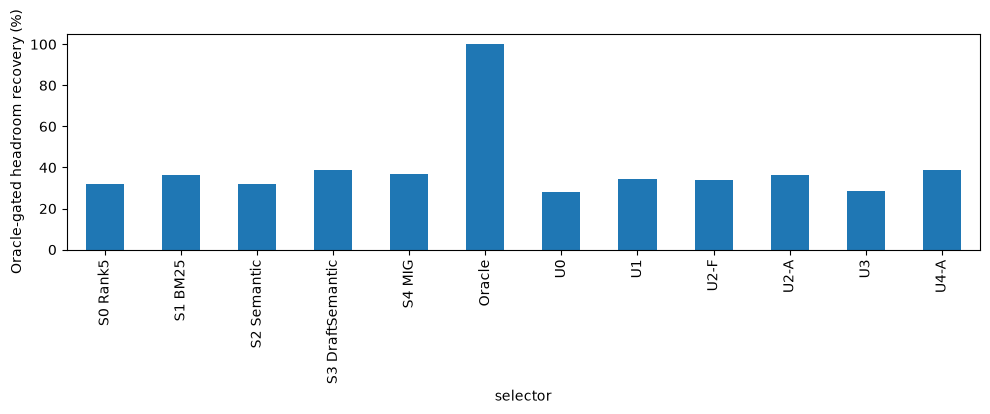

Actual baseline and oracle F1 are recomputed for this split; no hard-coded reference F1.


In [16]:
import matplotlib.pyplot as plt
comparison['selector_headroom_recovery'].mul(100).plot.bar(figsize=(10,4), ylabel='Oracle-gated headroom recovery (%)')
plt.axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()
print('Actual baseline and oracle F1 are recomputed for this split; no hard-coded reference F1.')


## SECTION 15 — Select using FIT OOF only


In [17]:
eligible = [name for name in MODELS if name in oof_predictions]
assert eligible, 'Run at least one model OOF cell before selecting.'
best_name = max(eligible, key=lambda name: fit_metrics[name]['selector_headroom_recovery'])
print('Selected:', best_name, '| FIT OOF SHR:', fit_metrics[best_name]['selector_headroom_recovery'])
print('INTERNAL-VAL has not influenced model selection.')


Selected: U4-A | FIT OOF SHR: 0.3901042109839281
INTERNAL-VAL has not influenced model selection.


## SECTION 16 — Refit selected model on full FIT


In [18]:
final_model = fit_final(best_name, df_fit, feature_cols, TRAIN)
print('Actual full-FIT training complete:', best_name)


U4-A epoch 1/3: 100%|██████████| 1746/1746 [00:17<00:00, 102.27it/s]

U4-A epoch 1: training loss=1.42973



U4-A epoch 2/3: 100%|██████████| 1746/1746 [00:17<00:00, 100.36it/s]

U4-A epoch 2: training loss=1.41926



U4-A epoch 3/3: 100%|██████████| 1746/1746 [00:17<00:00, 97.67it/s] 

U4-A epoch 3: training loss=1.40274


Actual full-FIT training complete: U4-A


## SECTION 17 — Evaluate selected model on INTERNAL-VAL


In [19]:
# Cache in this kernel so rerunning this cell does not repeat the evaluation.
if 'heldout_result' in globals():
    raise RuntimeError('Held-out evaluation already ran in this kernel. Inspect heldout_result; do not retune on it.')
df_val = prepare_features(load_surface('internal_val'))
assert set(feature_cols) <= set(df_val.columns)
val_predictions = predict_final(best_name, final_model, df_val, feature_cols, TRAIN)
heldout_result = compute_query_grouped_selector_metrics(
    df_val.assign(score=val_predictions['utility_score']), selector_scores_col='score')
display(pd.Series(heldout_result, name=f'{best_name}: held-out INTERNAL-VAL'))
calibration = None
if 'prob_help' in val_predictions:
    calibration = compute_calibration_metrics(df_val.target_help_binary.to_numpy(), val_predictions['prob_help'])
    print('HELP Brier:', calibration['brier_score'], '| ECE:', calibration['ece'])
    display(calibration['decile_table'])
else:
    print('U3 uses utility/action heads; no candidate HELP probability calibration is claimed.')


Semantic/MIG features: 100%|██████████| 342/342 [01:25<00:00,  3.98it/s]


base_k4_f1                       0.389061
oracle_selective1_f1             0.480670
num_queries                    342.000000
top1_oracle_accuracy             0.777778
near_oracle_selection_rate       0.786550
mean_selected_delta_f1           0.019267
unconditional_downstream_f1      0.408329
num_promoted                   342.000000
mean_regret                      0.071695
median_regret                    0.000000
help_precision                   0.134503
hurt_rate                        0.070175
final_downstream_f1              0.415323
selector_headroom_recovery       0.286666
Name: U4-A: held-out INTERNAL-VAL, dtype: float64

HELP Brier: 0.09529080240800482 | ECE: 0.05212855735157397


,decile,bin_range,count,mean_pred_prob,observed_rate,calibration_error
0,1,"[0.0, 0.1]",1509,0.021027,0.074221,0.053194
1,2,"[0.1, 0.2]",177,0.152659,0.175141,0.022482
2,3,"[0.2, 0.3]",261,0.252247,0.222222,0.030025
3,4,"[0.3, 0.4]",105,0.322684,0.180952,0.141732


## SECTION 18 — Save measured results and reloadable selected model


In [20]:
from dataclasses import asdict
import joblib
out = REPO_ROOT / 'results/week8/w8c_utility'
out.mkdir(parents=True, exist_ok=True)
# Persist the actual selected model, including tokenizer/backbone configuration and scaler.
if best_name == 'U0':
    joblib.dump(final_model, out / 'selected_u0.joblib')
    model_file = 'selected_u0.joblib'
else:
    payload = {'model_name': best_name, 'training_config': asdict(TRAIN),
               'feature_cols': feature_cols, 'state_dict': {k:v.detach().cpu() for k,v in final_model.state_dict().items()}}
    if hasattr(final_model, 'scaler'):
        payload['scaler'] = final_model.scaler
    torch.save(payload, out / 'selected_neural.pt')
    model_file = 'selected_neural.pt'
comparison.to_csv(out / 'fit_oof_comparison.csv')
for name, pred in oof_predictions.items():
    pd.concat([df_fit[['question_id','paper_id','semantic_rank','candidate_passage_index']].reset_index(drop=True),
               pd.DataFrame(pred)], axis=1).to_csv(out / f'{name}_fit_oof_predictions.csv', index=False)
pd.concat([df_val[['question_id','paper_id','semantic_rank','candidate_passage_index']].reset_index(drop=True),
           pd.DataFrame(val_predictions)], axis=1).to_csv(out / 'selected_internal_val_predictions.csv', index=False)
if calibration is not None:
    calibration['decile_table'].to_csv(out / 'selected_calibration.csv', index=False)
frozen = {'selected_model': best_name, 'model_file': model_file, 'models_compared': eligible,
          'training_config': asdict(TRAIN), 'feature_columns': feature_cols,
          'fit_oof_metrics': fit_metrics[best_name], 'internal_val_metrics': heldout_result,
          'feature_policy': 'canonical draft + tabular + measured MiniLM MIG; no W8-B token diagnostics or W8-D attribution',
          'gate': 'oracle epsilon=0.01; deployed controller remains W8-E',
          'surface_sha256': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [fit_path, val_path]}}
(out / 'w8c_frozen_selector_config.json').write_text(json.dumps(frozen, indent=2))
print('Saved measured W8-C results and selected model to', out)
# Reload later: from src.week8.utility_training import load_selected_model
# name, model, columns, settings = load_selected_model(out, device=TRAIN.device)


Saved measured W8-C results and selected model to /home/gunavenkat/Downloads/CS787-RAG-Project/results/week8/w8c_utility
